# Entrenamiento del modelo 

En este cuaderno, vamos a codificar todo el entrenamiento de la red neuronal a partir de la limpieza de datos previamente efectuada

In [9]:
!pip install torch
%pip install --upgrade --force-reinstall typing_extensions

  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached typing_extensions-4.16.0-py3-none-any.whl (45 kB)
  Attempting uninstall: typing_extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

En este primer apartado, vamos a hacer la división estratificada, es decir, definir qué parte de todo el dataset se va a usar para el entrenamiento y qué otra pequeña parte del mismo, se va a usar para la prueba de la red neuronal

Es importante tomar un dataset de prueba porque tenemos en ese pequeño dataset los resultados originales y se pretende evaluar, luego del entrenamiento, si la red neuronal llega a los mismos resultados o no. 



In [8]:
# Fijar semillas para reproducibilidad
torch.manual_seed(42)
np.random.seed(42)

# Cargar dataset limpio
df = pd.read_csv("nhanes_ir_clean.csv")
X = df.drop(columns=["insulino_resistente"])
y = df["insulino_resistente"]

# División estratificada (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Pipeline de imputación (mediana) y escalado estándar
preprocessor = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

## Entrenamiento de un modelo de regresión logística

Dado que cada una de las neuronas efectivamente ejecuta una regresión lineal, para poder ver el resultado final de la red neuronal (es decir: es insulino-resistente o no lo es) como una clasificación en dos categorías (llámesen 0 y 1), es necesario entrenar una regresión logística. 

In [9]:
baseline = LogisticRegression(random_state=42)
baseline.fit(X_train_scaled, y_train)
y_pred_base = baseline.predict_proba(X_test_scaled)[:, 1]
print(f"ROC-AUC Baseline (Regresión Logística): {roc_auc_score(y_test, y_pred_base):.4f}")


ROC-AUC Baseline (Regresión Logística): 0.8625


In [16]:
print(type(len(X.columns)), len(X.columns))

<class 'int'> 9


## Creación del Perceptrón de múltiples capas (MLP)

En la siguiente celda de código, se crea la clase InsulinResistanceNN que representa la red neuronal que va a ayudar a categorizar a los pacientes en "insulino-resistentes" o "no insulino-resistentes" (sensible).

Haciendo un análisis más profundo en la red neuronal, se puede observar que que el constructor recibe la cantidad de features que va a tener. 
Se puede observar que hay tres capas en total (por cada nn.Linear(), se crea una capa nueva en la red neuronal). 

- La primera capa va a tener una cantidad de entradas equivalente a las que se le pase por el constructor y una cantidad de 32 salidas
- La segunda capa va a tener 32 entradas y 16 salidas.
- La tercera capa va a tener 16 entradas y una única salida, lo cual es lógico, porque por más compleja que sea una red neuronal, hay que recordar que siempre devuelve un solo resultado

La función de activación es la RELU (Rectilínea Linear Uniforme). Esto significa que cada neurona en las capas va a estar recibiendo muchas funciones RELU hasta que la última neurona, en la capa de "output", va a hacer una suma ponderada de las últimas 16 funciones RELU que reciba de cada neurona de la anteúltima capa. Ese resultado va a formar un plano sobre el cual se efectúa la división categórica y se puede visualizar de manera bidimensional

Con PyTorch, se trabaja de manera cercana con la red neuronal porque se la entrena de manera iterativamente y además se optimiza, utilizando el método matemático del descenso del gradiente, lo cual justifica el uso de RELU




In [17]:
# Convertir a tensores de PyTorch
train_dataset = TensorDataset(
    torch.tensor(X_train_scaled, dtype=torch.float32),
    torch.tensor(y_train.to_numpy(), dtype=torch.float32).unsqueeze(1),
)
test_X_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)


# Definir la arquitectura MLP
class InsulinResistanceNN(nn.Module):

  def __init__(self, n_features):
    super().__init__()
    self.fc1 = nn.Linear(n_features, 32)
    self.bn1 = nn.BatchNorm1d(32)
    self.relu1 = nn.ReLU()
    self.drop1 = nn.Dropout(0.3)

    self.fc2 = nn.Linear(32, 16)
    self.bn2 = nn.BatchNorm1d(16)
    self.relu2 = nn.ReLU()
    self.drop2 = nn.Dropout(0.2)

    self.fc3 = nn.Linear(16, 1)

  def forward(self, x):
    x = self.drop1(self.relu1(self.bn1(self.fc1(x))))
    x = self.drop2(self.relu2(self.bn2(self.fc2(x))))
    return self.fc3(x)


model = InsulinResistanceNN(n_features=9)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

# Bucle de entrenamiento
epochs = 60
for epoch in range(epochs):
  model.train()
  for batch_X, batch_y in train_loader:
    optimizer.zero_grad()
    outputs = model(batch_X)
    loss = criterion(outputs, batch_y)
    loss.backward()
    optimizer.step()

print("¡Entrenamiento finalizado con éxito!")


¡Entrenamiento finalizado con éxito!


In [14]:
model = InsulinResistanceNN(input_dim=len(X.columns))

## Evaluación de la red neuronal a partir de ROC-AUC (Área bajo la curva de la característica operativa del receptor)

Utilizando los valores predichos y los valores reales, se calcula ROC-AUC, que permite medir qué tan bien distingue un modelo de clasificación binaria entre dos clases en todos los umbrales posibles. Esta métrica se bifurca en dos aspectos
- Curva ROC: Gráfico que compara la tasa de verdaderos positivos (sensibilidad) en el eje vertical frente a la tasa de falsos positivos (1 − especificidad) en el eje horizontal al variar el umbral de decisión
- AUC: Valor numérico entre 0 y 1 que resume el área bajo esa curva. Representa la probabilidad de que el modelo asigne una puntuación mayor a un caso positivo elegido al azar que a uno negativo elegido al azar.

La interpretación siempre va a depender del problema que se esté resolviendo. En este caso, para el AUC, cuanto mayor sea su valor, mejor funciona el modelo porque se quiere una probabilidad alta de que el modelo clasifique a un paciente meramente insulino-resistente, como tal. 

Para la matriz de confusión, hay que darle importancia en este caso a los falsos negativos, pues es más riesgoso que la red neuronal indique que un individuo no es insulino-resistente, cuando en realidad sí lo es. Acá es donde es crucial esta comparativa entre valores reales y valores predichos (o estimados)

ROC-AUC Red Neuronal: 0.8669

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.76      0.77      0.76       223
           1       0.79      0.78      0.78       245

    accuracy                           0.77       468
   macro avg       0.77      0.77      0.77       468
weighted avg       0.77      0.77      0.77       468



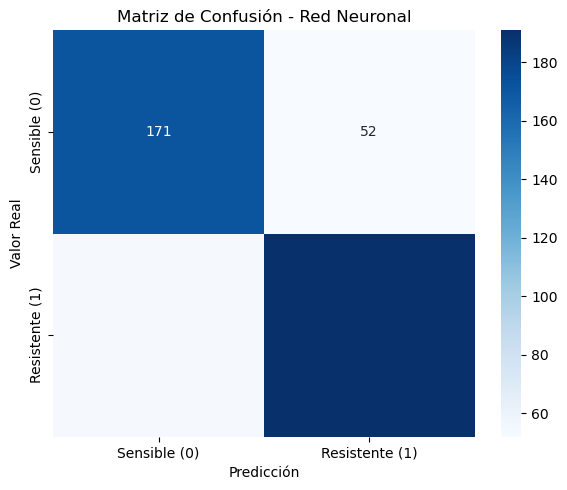

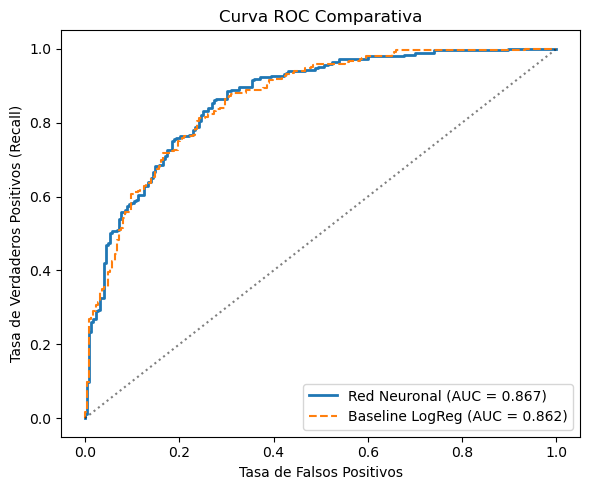

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

model.eval()
with torch.no_grad():
  logits = model(test_X_tensor)
  y_probs = torch.sigmoid(logits).numpy().flatten()
  y_preds = (y_probs >= 0.5).astype(int)

print(f"ROC-AUC Red Neuronal: {roc_auc_score(y_test, y_probs):.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_preds))

# 1. Gráfico de Matriz de Confusión
fig1, ax1 = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_preds)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax1,
    xticklabels=list(("Sensible (0)", "Resistente (1)")),
    yticklabels=list(("Sensible (0)", "Resistente (1)")),
)
ax1.set_title("Matriz de Confusión - Red Neuronal")
ax1.set_ylabel("Valor Real")
ax1.set_xlabel("Predicción")
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=300)
plt.show()

# 2. Gráfico de Curva ROC Comparativa
fig2, ax2 = plt.subplots(figsize=(6, 5))
fpr_nn, tpr_nn, _ = roc_curve(y_test, y_probs)
fpr_base, tpr_base, _ = roc_curve(y_test, y_pred_base)

ax2.plot(
    fpr_nn,
    tpr_nn,
    label=f"Red Neuronal (AUC = {roc_auc_score(y_test, y_probs):.3f})",
    lw=2,
)
ax2.plot(
    fpr_base,
    tpr_base,
    label=f"Baseline LogReg (AUC = {roc_auc_score(y_test, y_pred_base):.3f})",
    linestyle="--",
)
ax2.plot(list((0, 1)), list((0, 1)), "k:", alpha=0.5)
ax2.set_title("Curva ROC Comparativa")
ax2.set_xlabel("Tasa de Falsos Positivos")
ax2.set_ylabel("Tasa de Verdaderos Positivos (Recall)")
ax2.legend()
plt.tight_layout()
plt.savefig("curva_roc.png", dpi=300)
plt.show()



La interpretación de esta curva ROC-AUC parte de entender que el umbral se va bajando de 100% a 0%, y se van anotando dos cosas al mismo tiempo: los verdaderos positivos (¿cuántas personas fueron diagnosticadas como "insulino-resistentes" y lo eran realmente?) y los falsos positivos (¿cuántas personas fueron diagnosticadas como "insulino-resistentes" cuando, en realidad, no lo eran?). La gráfica simplemente cuenta en qué orden aparecen los positivos y los negativos cuando se ordenan datos de mayor a menor probabilidad. AUC es esa área cubierta gracias a la curva ROC y a esa recta que funciona como piso. 

In [22]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [24]:
%pip install --upgrade scipy scikit-learn


   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/8.3 MB 3.4 MB/s eta 0:00:03
    --------------------------------------- 0.1/8.3 MB 1.7 MB/s eta 0:00:05
    --------------------------------------- 0.2/8.3 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.3/8.3 MB 1.4 MB/s eta 0:00:06
   - -------------------------------------- 0.3/8.3 MB 1.4 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.3 MB 1.4 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.3 MB 1.3 MB/s eta 0:00:07
   -- ------------------------------------- 0.5/8.3 MB 1.3 MB/s eta 0:00:06
   -- ------------------------------------- 0.5/8.3 MB 1.3 MB/s eta 0:00:06
   -- ------------------------------------- 0.6/8.3 MB 1.3 MB/s eta 0:00:07
   --- ------------------------------------ 0.6/8.3 MB 1.3 MB/s eta 0:00:06
   --- ------------------------------------ 0.7/8.3 MB 1.3 MB/s eta 0:00:06
   --- ------------

## Análisis de Importancia de Variables mediante Permutation Importance

En la siguiente celda de código se determina la importancia de cada una de las variables clínicas de entrada (features) mediante la técnica de Permutation Importance. Este análisis es fundamental para la interpretabilidad del modelo, ya que permite cuantificar cuánto depende la red neuronal de cada dato para realizar sus predicciones, más allá de la complejidad de los pesos internos aprendidos en sus capas.


En el paso 1 se obtiene el puntaje ROC-AUC base del modelo sobre el conjunto de prueba intacto. Luego, en el paso 2, mediante un bucle for, se desordena aleatoriamente (permuta) cada columna por separado —repitiendo el proceso 20 veces para estabilizar el resultado— y se mide cuánto cae el ROC-AUC al convertir esa variable en ruido. Finalmente, en el paso 3, se visualiza mediante un gráfico de barras horizontales la caída promedio del rendimiento asociada a cada variable, facilitando la interpretación visual de cuáles son los factores más influyentes para el diagnóstico del modelo.


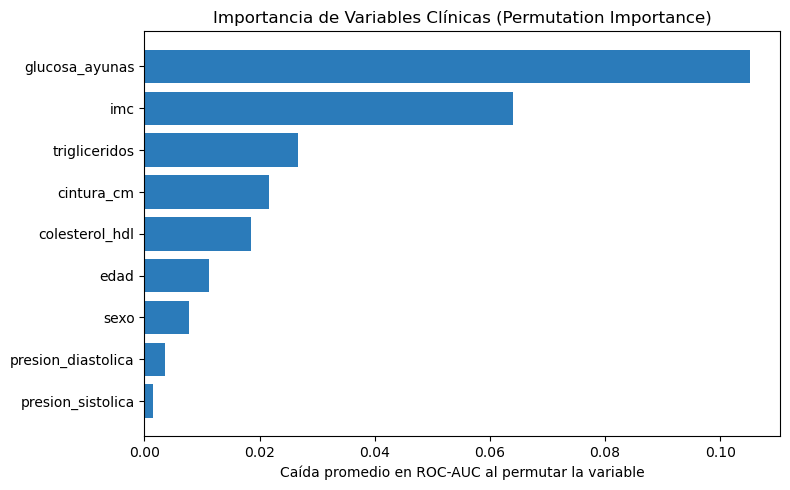

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
import torch

# 1. Calcular el AUC base de tu red neuronal
model.eval()
with torch.no_grad():
  base_probs = torch.sigmoid(model(test_X_tensor)).numpy().flatten()
base_auc = roc_auc_score(y_test, base_probs)

# 2. Medir cuánto cae el AUC al desordenar cada columna (Permutation Importance puro)
np.random.seed(42)
importancias = {}

for col_idx, col_name in enumerate(X.columns):
  caidas = []
  for _ in range(20):  # 20 repeticiones por variable
    X_permuted = X_test_scaled.copy()
    X_permuted[:, col_idx] = np.random.permutation(X_permuted[:, col_idx])

    with torch.no_grad():
      perm_probs = (
          torch.sigmoid(model(torch.tensor(X_permuted, dtype=torch.float32)))
          .numpy()
          .flatten()
      )
    caidas.append(base_auc - roc_auc_score(y_test, perm_probs))

  importancias[col_name] = np.mean(caidas)

# 3. Graficar usando ax.barh() directamente (sin usar pandas .plot)
serie_imp = pd.Series(importancias).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(serie_imp.index, serie_imp.values, color="#2b7bba")
ax.set_title("Importancia de Variables Clínicas (Permutation Importance)")
ax.set_xlabel("Caída promedio en ROC-AUC al permutar la variable")
plt.tight_layout()
plt.savefig("importancia_variables.png", dpi=300)
plt.show()



In [28]:
import joblib

torch.save(model.state_dict(), "insulin_resistance_mlp.pth")
joblib.dump(preprocessor, "preprocessor.pkl")
print("Archivos guardados con éxito")


¡Archivos guardados con éxito!
